# Phần B. Chất lượng và thời gian của dữ liệu VN1

**Đề tài:** Dự báo doanh thu 13 tuần tới theo nhóm kiểu nhu cầu cho sản phẩm của nhà bán hàng trực tuyến (dữ liệu VN1)

Notebook này kiểm tra chất lượng bộ dữ liệu VN1 theo cấu trúc của notebook hướng dẫn (dòng trùng, giá trị thiếu, giá trị mâu thuẫn, thời gian và chia tập, phân bố giá, tóm tắt), sau đó chấm điểm theo 6 chiều chất lượng cốt lõi của DAMA bằng thước đo tỷ lệ đơn giản `1 − số lỗi / số đơn vị`, đo **trước** (trên `raw/`) và **sau** làm sạch (trên `clean/`), theo dõi theo tuần, và kiểm tra rò rỉ.

- Chỉ đọc `raw/` và `clean/`; kết quả ghi vào `reports/dq/`.
- Hạt dữ liệu (grain): **một chuỗi × một tuần**. Một chuỗi là một bộ Client × Warehouse × Product.
- Phần chính dùng Phase 0 + Phase 1 (183 tuần có cả số lượng và giá). Phase 2 chỉ có số lượng.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
RAW, CLEAN, OUT = os.path.join(ROOT, "raw"), os.path.join(ROOT, "clean"), os.path.join(ROOT, "reports", "dq")
os.makedirs(OUT, exist_ok=True)
KEYS = ["Client", "Warehouse", "Product"]
FILES = ["Phase 0 - Sales.csv", "Phase 0 - Price.csv", "Phase 1 - Sales.csv", "Phase 1 - Price.csv", "Phase 2 - Sales.csv"]
pd.set_option("display.float_format", lambda v: f"{v:,.6g}")
BLUE, ORANGE, AQUA, GRAY, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110})

raw_str = {f: pd.read_csv(os.path.join(RAW, f), dtype=str, keep_default_na=False) for f in FILES}   # đọc nguyên văn
raw = {f: pd.read_csv(os.path.join(RAW, f)) for f in FILES}                                        # đọc dạng số
pd.DataFrame([{"file": f, "số dòng": len(d), "số cột": d.shape[1], "số cột tuần": d.shape[1] - 3,
               "tuần đầu": d.columns[3], "tuần cuối": d.columns[-1]} for f, d in raw.items()])

,file,số dòng,số cột,số cột tuần,tuần đầu,tuần cuối
0,Phase 0 - Sales.csv,15053,173,170,2020-07-06,2023-10-02
1,Phase 0 - Price.csv,15053,173,170,2020-07-06,2023-10-02
2,Phase 1 - Sales.csv,15053,16,13,2023-10-09,2024-01-01
3,Phase 1 - Price.csv,15053,16,13,2023-10-09,2024-01-01
4,Phase 2 - Sales.csv,15053,16,13,2024-01-08,2024-04-01


## 1. Dòng trùng

Kiểm tra ba mức: dòng trùng hoàn toàn, trùng khóa (Client, Warehouse, Product) trong từng file gốc, và trùng (chuỗi, tuần) trong bảng dài đã làm sạch.

In [2]:
dup = pd.DataFrame([{"file": f, "số dòng": len(d), "dòng trùng hoàn toàn": int(d.duplicated().sum()),
                     "khóa trùng (Client, Warehouse, Product)": int(d.duplicated(KEYS).sum())} for f, d in raw_str.items()])
long = pd.read_parquet(os.path.join(CLEAN, "vn1_long.parquet"))
p2 = pd.read_parquet(os.path.join(CLEAN, "vn1_phase2_sales.parquet"))
dup_long = pd.DataFrame([{"file": "clean/vn1_long.parquet", "số dòng": len(long), "trùng (unique_id, week)": int(long.duplicated(["unique_id", "week"]).sum())},
                         {"file": "clean/vn1_phase2_sales.parquet", "số dòng": len(p2), "trùng (unique_id, week)": int(p2.duplicated(["unique_id", "week"]).sum())}])
dup.to_csv(os.path.join(OUT, "dq_duplicates_raw.csv"), index=False); dup_long.to_csv(os.path.join(OUT, "dq_duplicates_clean.csv"), index=False)
display(dup, dup_long)

,file,số dòng,dòng trùng hoàn toàn,"khóa trùng (Client, Warehouse, Product)"
0,Phase 0 - Sales.csv,15053,0,0
1,Phase 0 - Price.csv,15053,0,0
2,Phase 1 - Sales.csv,15053,0,0
3,Phase 1 - Price.csv,15053,0,0
4,Phase 2 - Sales.csv,15053,0,0


,file,số dòng,"trùng (unique_id, week)"
0,clean/vn1_long.parquet,1615437,0
1,clean/vn1_phase2_sales.parquet,195689,0


## 2. Giá trị thiếu

Ba loại: (a) ô trống, và ô trống đó là "không áp dụng" hay thiếu thật; (b) giá trị giả dạng thiếu; (c) thiếu cả dòng hoặc cả tuần.

### 2a. Ô trống theo file

In [3]:
def wide_matrix(name):
    d = raw[name].set_index(KEYS).sort_index()
    return d

S0, P0, S1, P1, S2 = (wide_matrix(f) for f in FILES)
S = pd.concat([S0, S1], axis=1); P = pd.concat([P0, P1.reindex(P0.index)], axis=1).reindex(S.index)
weeks = pd.to_datetime(S.columns)
Sv, Pv = S.to_numpy(dtype=float), P.to_numpy(dtype=float)
n_series, n_weeks = Sv.shape
n_cells = Sv.size
sale = Sv > 0
miss = pd.DataFrame([{"file": f, "số ô": d.shape[0] * (d.shape[1] - 3), "ô trống": int(d.iloc[:, 3:].isna().sum().sum()),
                      "% trống": d.iloc[:, 3:].isna().sum().sum() / (d.shape[0] * (d.shape[1] - 3)) * 100,
                      "ô trống ở cột khóa": int(d[KEYS].isna().sum().sum())} for f, d in raw.items()])
miss.to_csv(os.path.join(OUT, "dq_missing_by_file.csv"), index=False)
miss

,file,số ô,ô trống,% trống,ô trống ở cột khóa
0,Phase 0 - Sales.csv,2559010,0,0,0
1,Phase 0 - Price.csv,2559010,1836437,71.7636,0
2,Phase 1 - Sales.csv,195689,0,0,0
3,Phase 1 - Price.csv,195689,110059,56.2418,0
4,Phase 2 - Sales.csv,195689,0,0,0


Ô trống chỉ có ở hai file giá. Bảng dưới đối chiếu từng ô giá với ô số lượng tương ứng để xem ô trống là **cấu trúc** (tuần đó không bán nên không có giá, tức "không áp dụng") hay **thiếu thật** (có bán mà không có giá).

In [4]:
p_empty = np.isnan(Pv)
struct = pd.DataFrame({
    "tình huống": ["sales = 0 và giá trống (không áp dụng)", "sales = 0 nhưng có giá", "sales > 0 và giá trống (thiếu thật)", "sales > 0 và có giá"],
    "số ô": [int((~sale & p_empty).sum()), int((~sale & ~p_empty).sum()), int((sale & p_empty).sum()), int((sale & ~p_empty).sum())]})
struct["% tổng số ô"] = struct["số ô"] / n_cells * 100
struct.to_csv(os.path.join(OUT, "dq_missing_structural.csv"), index=False)
struct

,tình huống,số ô,% tổng số ô
0,sales = 0 và giá trống (không áp dụng),1946496,70.6609
1,sales = 0 nhưng có giá,0,0
2,sales > 0 và giá trống (thiếu thật),0,0
3,sales > 0 và có giá,808203,29.3391


### 2b. Giá trị giả dạng thiếu

Tìm các chuỗi ký tự thường dùng thay cho giá trị thiếu, và các số giữ chỗ (âm, hoặc 0 ở nơi 0 không có nghĩa).

In [5]:
TOKENS = ["nan", "null", "none", "na", "n/a", "unknown", "-", "?", "missing", "#n/a"]
rows = []
for f, d in raw_str.items():
    v = d.iloc[:, 3:].to_numpy().ravel()
    low = np.char.lower(np.char.strip(v.astype(str)))
    num = pd.to_numeric(pd.Series(v), errors="coerce").to_numpy()
    rows.append({"file": f, "chuỗi rỗng ''": int((low == "").sum()), "token giả thiếu (nan, null, unknown, -, ...)": int(np.isin(low, TOKENS).sum()),
                 "không chuyển được sang số (trừ rỗng)": int((np.isnan(num) & (low != "")).sum()), "giá trị âm": int((num < 0).sum()),
                 "giá trị bằng 0": int((num == 0).sum()), "giá trị 999/9999/99999": int(np.isin(num, [999, 9999, 99999]).sum())})
disg = pd.DataFrame(rows)
disg.to_csv(os.path.join(OUT, "dq_disguised_missing.csv"), index=False)
display(disg)
zero_price_sale = sale & (Pv == 0)
print(f"Giá bằng 0 ở tuần có bán (Phase 0+1): {zero_price_sale.sum():,} ô, thuộc {zero_price_sale.any(axis=1).sum():,} chuỗi; "
      f"trong đó {(zero_price_sale.sum(axis=1) == sale.sum(axis=1))[sale.any(axis=1)].sum()} chuỗi có giá bằng 0 ở MỌI tuần có bán.")

,file,chuỗi rỗng '',"token giả thiếu (nan, null, unknown, -, ...)",không chuyển được sang số (trừ rỗng),giá trị âm,giá trị bằng 0,giá trị 999/9999/99999
0,Phase 0 - Sales.csv,0,0,0,0,1836437,5
1,Phase 0 - Price.csv,1836437,0,0,0,4755,24
2,Phase 1 - Sales.csv,0,0,0,0,110059,0
3,Phase 1 - Price.csv,110059,0,0,0,850,4
4,Phase 2 - Sales.csv,0,0,0,0,117297,0


Giá bằng 0 ở tuần có bán (Phase 0+1): 5,605 ô, thuộc 1,657 chuỗi; trong đó 64 chuỗi có giá bằng 0 ở MỌI tuần có bán.


Số 0 trong file Sales là giá trị thật (tuần không bán). Số 0 trong file Price thì khác: giá bằng 0 ở tuần có bán không phải là giá, nên đó là **giá trị giả dạng thiếu**.

### 2c. Thiếu cả dòng hoặc cả tuần

In [6]:
cal_rows = []
for f, d in raw.items():
    w = pd.to_datetime(d.columns[3:])
    gaps = np.diff(w.values).astype("timedelta64[D]").astype(int)
    cal_rows.append({"file": f, "số tuần": len(w), "tuần đầu": w[0].date(), "tuần cuối": w[-1].date(), "mọi cột là thứ Hai": bool((w.dayofweek == 0).all()),
                     "mọi khoảng cách = 7 ngày": bool((gaps == 7).all()), "cột tuần trùng": int(pd.Index(d.columns[3:]).duplicated().sum())})
cal = pd.DataFrame(cal_rows)
keysets = {f: set(map(tuple, d[KEYS].to_numpy())) for f, d in raw.items()}
ref = keysets[FILES[0]]
keyeq = pd.DataFrame([{"file": f, "số khóa": len(k), "thiếu so với Phase 0 - Sales": len(ref - k), "thừa so với Phase 0 - Sales": len(k - ref)} for f, k in keysets.items()])
cont = pd.DataFrame([
    {"nối": "Phase 0 → Phase 1", "tuần cuối trước": S0.columns[-1], "tuần đầu sau": S1.columns[0], "cách nhau (ngày)": (pd.Timestamp(S1.columns[0]) - pd.Timestamp(S0.columns[-1])).days},
    {"nối": "Phase 1 → Phase 2", "tuần cuối trước": S1.columns[-1], "tuần đầu sau": S2.columns[0], "cách nhau (ngày)": (pd.Timestamp(S2.columns[0]) - pd.Timestamp(S1.columns[-1])).days}])
same_cols = pd.DataFrame([{"cặp": "Phase 0 Sales và Price", "cột tuần giống hệt": list(S0.columns) == list(P0.columns)},
                          {"cặp": "Phase 1 Sales và Price", "cột tuần giống hệt": list(S1.columns) == list(P1.columns)}])
cal.to_csv(os.path.join(OUT, "dq_calendar.csv"), index=False); keyeq.to_csv(os.path.join(OUT, "dq_keysets.csv"), index=False)
display(cal, cont, same_cols, keyeq)

,file,số tuần,tuần đầu,tuần cuối,mọi cột là thứ Hai,mọi khoảng cách = 7 ngày,cột tuần trùng
0,Phase 0 - Sales.csv,170,2020-07-06,2023-10-02,True,True,0
1,Phase 0 - Price.csv,170,2020-07-06,2023-10-02,True,True,0
2,Phase 1 - Sales.csv,13,2023-10-09,2024-01-01,True,True,0
3,Phase 1 - Price.csv,13,2023-10-09,2024-01-01,True,True,0
4,Phase 2 - Sales.csv,13,2024-01-08,2024-04-01,True,True,0


,nối,tuần cuối trước,tuần đầu sau,cách nhau (ngày)
0,Phase 0 → Phase 1,2023-10-02,2023-10-09,7
1,Phase 1 → Phase 2,2024-01-01,2024-01-08,7


,cặp,cột tuần giống hệt
0,Phase 0 Sales và Price,True
1,Phase 1 Sales và Price,True


,file,số khóa,thiếu so với Phase 0 - Sales,thừa so với Phase 0 - Sales
0,Phase 0 - Sales.csv,15053,0,0
1,Phase 0 - Price.csv,15053,0,0
2,Phase 1 - Sales.csv,15053,0,0
3,Phase 1 - Price.csv,15053,0,0
4,Phase 2 - Sales.csv,15053,0,0


## 3. Giá trị mâu thuẫn

Mỗi quy tắc cho biết số vi phạm, số đơn vị được kiểm tra và tỷ lệ. Quy tắc không có vi phạm vẫn được giữ trong bảng để thấy đã kiểm tra.

In [7]:
rules = []
def add(rule, nhom, viol, total, note=""):
    rules.append({"quy tắc": rule, "nhóm": nhom, "vi phạm": int(viol), "tổng kiểm tra": int(total), "%": viol / total * 100 if total else 0.0, "ghi chú": note})

all_sales = np.concatenate([Sv.ravel(), S2.to_numpy(dtype=float).ravel()])
add("R1  sales < 0", "miền giá trị", (all_sales < 0).sum(), all_sales.size, "cả 3 phase")
add("R2  sales không phải số nguyên", "miền giá trị", (all_sales != np.round(all_sales)).sum(), all_sales.size, "cả 3 phase")
add("R3  giá <= 0 khi sales > 0", "miền giá trị", (sale & (Pv <= 0)).sum(), sale.sum(), "giá 0 là giá trị giả dạng thiếu")
add("R4  có giá khi sales = 0", "liên trường", (~sale & ~p_empty).sum(), (~sale).sum())
add("R5  giá trống khi sales > 0", "liên trường", (sale & p_empty).sum(), sale.sum())

# R6: cùng Product, cùng tuần, giá chênh > 10 lần giữa các chuỗi
obs = sale & (Pv > 0)
r, c = np.nonzero(obs)
pl = pd.DataFrame({"product": S.index.get_level_values("Product").to_numpy()[r], "week": c, "price": Pv[r, c]})
g = pl.groupby(["product", "week"])["price"].agg(["min", "max", "size"])
g = g[g["size"] >= 2]
add("R6  cùng sản phẩm, cùng tuần, giá chênh > 10 lần giữa các chuỗi", "proxy chính xác", (g["max"] / g["min"] > 10).sum(), len(g), "đơn vị: cặp (sản phẩm, tuần) có từ 2 giá")

# R7: giá nhảy > 10 lần so với tuần liền trước trong cùng chuỗi
both = obs[:, 1:] & obs[:, :-1]
with np.errstate(divide="ignore", invalid="ignore"):
    ratio = np.where(both, Pv[:, 1:] / Pv[:, :-1], np.nan)
jump = both & ((ratio > 10) | (ratio < 0.1))
add("R7  giá nhảy > 10 lần so với tuần liền trước", "proxy chính xác", jump.sum(), both.sum(), "đơn vị: cặp tuần liền nhau đều có giá")

# R8: đột biến > 20 lần trung vị các tuần có bán
med = np.nanmedian(np.where(sale, Sv, np.nan), axis=1)
spike = Sv > 20 * med[:, None]
add("R8  sales > 20 lần trung vị các tuần có bán của chuỗi", "proxy chính xác", spike.sum(), sale.sum(), "phần lớn là mùa cao điểm, xem phần EDA")

# R9: chuỗi giá trị lặp lại y hệt >= 13 tuần liên tiếp (khác 0)
run = np.where(sale[:, 0], 1, 0); flagged = np.zeros(n_series, dtype=int); const_cells = np.zeros(n_weeks, dtype=int)
runlen = np.zeros_like(Sv, dtype=int); runlen[:, 0] = run
for t in range(1, n_weeks):
    run = np.where(sale[:, t] & (Sv[:, t] == Sv[:, t - 1]), run + 1, np.where(sale[:, t], 1, 0)); runlen[:, t] = run
# đánh dấu ngược mọi ô thuộc một đoạn lặp >= 13
in_run = np.zeros_like(sale); carry = np.zeros(n_series, dtype=int)
for t in range(n_weeks - 1, -1, -1):
    carry = np.where(runlen[:, t] >= 13, runlen[:, t], np.where((carry > 1) & (runlen[:, t] > 0), carry - 1, 0))
    in_run[:, t] = carry > 0
    carry = np.where(runlen[:, t] == 1, 0, carry)
add("R9  sales lặp lại y hệt >= 13 tuần liên tiếp", "proxy chính xác", in_run.sum(), sale.sum(), f"{in_run.any(axis=1).sum()} chuỗi; dấu hiệu giá trị được điền")

add("R10 Phase 1 bắt đầu đúng 7 ngày sau Phase 0", "thời gian", int(cont.loc[0, "cách nhau (ngày)"] != 7), 1)
add("R11 Phase 2 bắt đầu đúng 7 ngày sau Phase 1", "thời gian", int(cont.loc[1, "cách nhau (ngày)"] != 7), 1)
add("R12 khóa của Phase 2 giống hệt Phase 1", "liên file", len(keysets[FILES[4]] ^ keysets[FILES[2]]), len(keysets[FILES[2]]))
add("R13 khóa của file Price giống hệt file Sales (Phase 0, 1)", "liên file", len(keysets[FILES[0]] ^ keysets[FILES[1]]) + len(keysets[FILES[2]] ^ keysets[FILES[3]]), 2 * len(ref))
add("R14 chuỗi không bán gì trong cả Phase 0 + 1", "liên trường", (~sale.any(axis=1)).sum(), n_series)
rules_df = pd.DataFrame(rules)
rules_df.to_csv(os.path.join(OUT, "dq_rules.csv"), index=False)
rules_df

,quy tắc,nhóm,vi phạm,tổng kiểm tra,%,ghi chú
0,R1 sales < 0,miền giá trị,0,2950388,0,cả 3 phase
1,R2 sales không phải số nguyên,miền giá trị,0,2950388,0,cả 3 phase
2,R3 giá <= 0 khi sales > 0,miền giá trị,5605,808203,0.693514,giá 0 là giá trị giả dạng thiếu
3,R4 có giá khi sales = 0,liên trường,0,1946496,0,
4,R5 giá trống khi sales > 0,liên trường,0,808203,0,
5,"R6 cùng sản phẩm, cùng tuần, giá chênh > 10 l...",proxy chính xác,3357,108983,3.0803,"đơn vị: cặp (sản phẩm, tuần) có từ 2 giá"
6,R7 giá nhảy > 10 lần so với tuần liền trước,proxy chính xác,354,669492,0.0528759,đơn vị: cặp tuần liền nhau đều có giá
7,R8 sales > 20 lần trung vị các tuần có bán củ...,proxy chính xác,1495,808203,0.184978,"phần lớn là mùa cao điểm, xem phần EDA"
8,R9 sales lặp lại y hệt >= 13 tuần liên tiếp,proxy chính xác,20557,808203,2.54354,374 chuỗi; dấu hiệu giá trị được điền
9,R10 Phase 1 bắt đầu đúng 7 ngày sau Phase 0,thời gian,0,1,0,


In [8]:
# R9 chi tiết: các đoạn lặp tập trung ở đâu
ri, ci = np.nonzero(in_run)
rep = pd.DataFrame({"client": S.index.get_level_values("Client").to_numpy()[ri], "giá trị lặp": Sv[ri, ci].astype(int)})
display(rep.groupby("client").size().sort_values(ascending=False).head(5).rename("số ô trong đoạn lặp").to_frame(),
        rep.groupby("giá trị lặp").size().sort_values(ascending=False).head(5).rename("số ô").to_frame())

,số ô trong đoạn lặp
client,
0,20544
22,13


,số ô
giá trị lặp,
7,17473
14,1348
21,916
28,205
49,92


## 4. Thời gian và chia tập

In [9]:
per_year = pd.Series(1, index=weeks).groupby(weeks.year).sum().rename("số tuần (Phase 0+1)").to_frame()
w2 = pd.to_datetime(S2.columns)
per_year["số tuần Phase 2"] = pd.Series(1, index=w2).groupby(w2.year).sum()
per_year = per_year.fillna(0).astype(int)
TEST_WEEKS, H = 52, 13
n_train = n_weeks - TEST_WEEKS
full_cal = pd.date_range(weeks[0], w2[-1], freq="7D")
time_box = pd.DataFrame({"mục": ["Khoảng thời gian Phase 0+1", "Phase 2 (chỉ số lượng, không có giá)", "Tổng số tuần liên tục", "Tuần thiếu trong lịch",
                                 "Huấn luyện", "Kiểm tra", "Mốc dự báo 13 tuần không chồng nhau trong tập kiểm tra", "Mốc dự báo 13 tuần nếu trượt từng tuần"],
                         "giá trị": [f"{weeks[0].date()} .. {weeks[-1].date()} ({n_weeks} tuần)", f"{w2[0].date()} .. {w2[-1].date()} ({len(w2)} tuần)",
                                     f"{len(full_cal)} (lịch đầy đủ) so với {n_weeks + len(w2)} (trong dữ liệu)", len(set(full_cal) - set(weeks) - set(w2)),
                                     f"{n_train} tuần, {weeks[0].date()} .. {weeks[n_train - 1].date()}", f"{TEST_WEEKS} tuần, {weeks[n_train].date()} .. {weeks[-1].date()}",
                                     f"{TEST_WEEKS // H}: " + ", ".join(str(weeks[n_train + H * k].date()) for k in range(TEST_WEEKS // H)), TEST_WEEKS - H + 1]})
time_box.to_csv(os.path.join(OUT, "dq_time_split.csv"), index=False)
display(per_year, time_box)

,số tuần (Phase 0+1),số tuần Phase 2
2020,26,0
2021,52,0
2022,52,0
2023,52,0
2024,1,13


,mục,giá trị
0,Khoảng thời gian Phase 0+1,2020-07-06 .. 2024-01-01 (183 tuần)
1,"Phase 2 (chỉ số lượng, không có giá)",2024-01-08 .. 2024-04-01 (13 tuần)
2,Tổng số tuần liên tục,196 (lịch đầy đủ) so với 196 (trong dữ liệu)
3,Tuần thiếu trong lịch,0
4,Huấn luyện,"131 tuần, 2020-07-06 .. 2023-01-02"
5,Kiểm tra,"52 tuần, 2023-01-09 .. 2024-01-01"
6,Mốc dự báo 13 tuần không chồng nhau trong tập ...,"4: 2023-01-09, 2023-04-10, 2023-07-10, 2023-10-09"
7,Mốc dự báo 13 tuần nếu trượt từng tuần,40


In [10]:
first_idx = sale.argmax(axis=1)
launch = pd.Series(1, index=weeks[first_idx]).groupby(weeks[first_idx].to_period("Q")).sum()
print(f"Chuỗi đã bán ngay tuần đầu của dữ liệu (ngày ra mắt thật không biết): {(first_idx == 0).sum():,}")
print(f"Chuỗi có lần bán đầu tiên nằm trong 52 tuần kiểm tra: {(first_idx >= n_train).sum():,}")
print(f"Chuỗi ra mắt sau 2023-10-02: {(first_idx > n_weeks - 14).sum()} (danh sách chuỗi được chốt theo Phase 0)")

Chuỗi đã bán ngay tuần đầu của dữ liệu (ngày ra mắt thật không biết): 2,224
Chuỗi có lần bán đầu tiên nằm trong 52 tuần kiểm tra: 3,727
Chuỗi ra mắt sau 2023-10-02: 0 (danh sách chuỗi được chốt theo Phase 0)


## 5. Phân bố và bất thường của giá

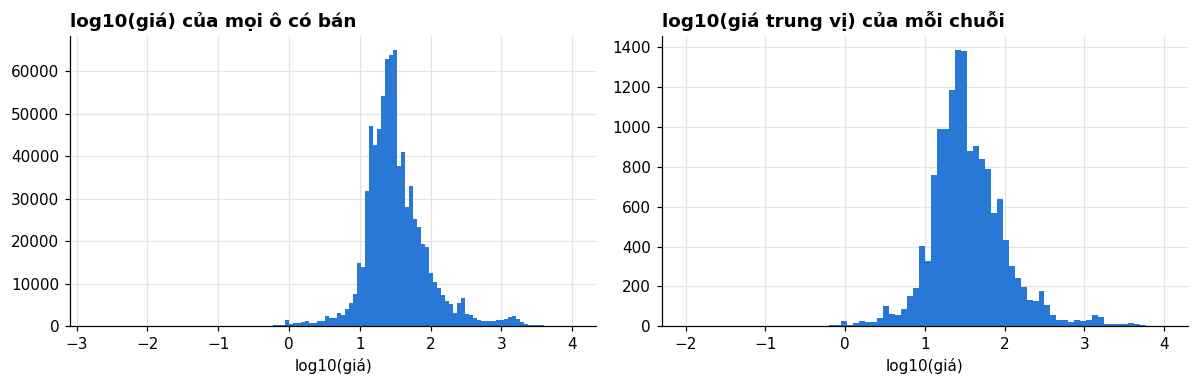

,phân vị,giá
0,"0,1%",0.568005
1,1%,2.16
2,25%,17.97
3,50%,28.0333
4,75%,50.99
5,99%,"1,349.1"
6,"99,9%","2,702.39"


BIC hỗn hợp Gauss trên log10(giá trung vị chuỗi): {1: 20317, 2: 18190, 3: 18109}
Hai thành phần (k=2): trung tâm = [28.8 53.8] , tỷ trọng = [0.7 0.3]
Giá trung vị theo nhà bán hàng: nhỏ nhất 9.95, trung vị 29.86, lớn nhất 1333.22 (chênh 134 lần)


In [11]:
from sklearn.mixture import GaussianMixture
price_obs = Pv[obs]
lp = np.log10(price_obs)
med_series = np.nanmedian(np.where(obs, Pv, np.nan), axis=1)
lm = np.log10(med_series[~np.isnan(med_series)])
rng = np.random.default_rng(0)
sample = rng.choice(lm, min(len(lm), 15000), replace=False).reshape(-1, 1)
bic = {k: GaussianMixture(k, random_state=0).fit(sample).bic(sample) for k in (1, 2, 3)}
gm2 = GaussianMixture(2, random_state=0).fit(sample)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(lp, bins=120, color=BLUE); axes[0].set_title("log10(giá) của mọi ô có bán"); axes[0].set_xlabel("log10(giá)")
axes[1].hist(lm, bins=80, color=BLUE); axes[1].set_title("log10(giá trung vị) của mỗi chuỗi"); axes[1].set_xlabel("log10(giá)")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig_dq01_phan_bo_gia.png")); plt.show()
q = np.quantile(price_obs, [0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999])
price_box = pd.DataFrame({"phân vị": ["0,1%", "1%", "25%", "50%", "75%", "99%", "99,9%"], "giá": q})
display(price_box)
print("BIC hỗn hợp Gauss trên log10(giá trung vị chuỗi):", {k: round(v) for k, v in bic.items()})
print("Hai thành phần (k=2): trung tâm =", np.round(10 ** gm2.means_.ravel(), 1), ", tỷ trọng =", np.round(gm2.weights_, 2))
cl = pd.DataFrame({"client": S.index.get_level_values("Client"), "med": med_series}).dropna().groupby("client")["med"].median()
print(f"Giá trung vị theo nhà bán hàng: nhỏ nhất {cl.min():.2f}, trung vị {cl.median():.2f}, lớn nhất {cl.max():.2f} (chênh {cl.max() / cl.min():.0f} lần)")
price_box.to_csv(os.path.join(OUT, "dq_price_quantiles.csv"), index=False)

Đơn vị tiền tệ không được công bố và các mã đều ẩn danh, nên không thể đối chiếu giá với nguồn bên ngoài. Thước đo MAE% không phụ thuộc đơn vị tiền nên điều này không ảnh hưởng tới việc đánh giá dự báo, nhưng doanh thu của các nhà bán hàng khác nhau chỉ cộng lại được nếu giả định chúng cùng một loại tiền.

## 6. Sáu chiều chất lượng DAMA, trước và sau làm sạch

Thước đo của mỗi chiều là `1 − số lỗi / số đơn vị`, nằm trong [0, 1]. Tính ở hạt dữ liệu (chuỗi × tuần), sau đó tổng hợp theo hai cách: gộp mọi ô của file ("theo ô"), và lấy điểm của từng chuỗi rồi trung bình ("theo chuỗi").

| Chiều | Đơn vị | Lỗi |
|---|---|---|
| Đầy đủ | giá trị bắt buộc: mọi ô sales, và ô giá ở tuần có bán | ô trống không mang nghĩa "không áp dụng" |
| Duy nhất | khóa (chuỗi, tuần) | khóa trùng |
| Hợp lệ | giá trị có mặt | sales âm hoặc không nguyên; giá <= 0 |
| Nhất quán | ô chuỗi × tuần | vi phạm quy tắc liên trường: có giá khi không bán, có bán mà không có giá; ở bản sạch thêm `revenue = sales × price` |
| Kịp thời | tuần trong lịch | tuần thiếu; kèm tuổi của dữ liệu so với hôm nay |
| Chính xác | (không có nguồn tham chiếu) | chỉ dùng proxy: R7 giá nhảy, R8 đột biến, R9 lặp lại |

In [12]:
def score(err, unit):
    """Điểm theo ô (gộp) và theo chuỗi (trung bình điểm từng chuỗi có đơn vị)."""
    err, unit = err.sum(axis=1).astype(float), unit.sum(axis=1).astype(float)
    has = unit > 0
    per = 1 - err[has] / unit[has]
    return {"theo ô": 1 - err.sum() / unit.sum(), "theo chuỗi": per.mean(), "chuỗi có lỗi": int((per < 1).sum()), "số lỗi": int(err.sum()), "số đơn vị": int(unit.sum())}

ones = np.ones_like(sale)
before = {
    "Đầy đủ": score(np.hstack([np.isnan(Sv), sale & p_empty]), np.hstack([ones, sale])),
    "Hợp lệ": score(np.hstack([(Sv < 0) | (Sv != np.round(Sv)), ~p_empty & (Pv <= 0)]), np.hstack([ones, ~p_empty])),
    "Nhất quán": score((~sale & ~p_empty) | (sale & p_empty), ones),
}
# Bản sạch: đưa về ma trận chuỗi x tuần (chỉ các ô từ tuần bán đầu tiên)
ids = long["unique_id"].unique()
piv = lambda col: long.pivot(index="unique_id", columns="week", values=col).reindex(index=ids)
cS, cP, cPraw, cR = (piv(c).to_numpy(dtype=float) for c in ("sales", "price", "price_raw", "revenue"))
present = ~np.isnan(cS)
csale = present & (cS > 0)
rev_expected = np.where(csale, cS * cP, 0.0)
rev_bad = present & ~np.isclose(np.nan_to_num(cR, nan=-1.0), np.nan_to_num(rev_expected, nan=-1.0), rtol=1e-9, atol=1e-9)
after = {
    "Đầy đủ": score(np.hstack([np.zeros_like(present), csale & np.isnan(cP)]), np.hstack([present, csale])),
    "Hợp lệ": score(np.hstack([present & ((cS < 0) | (cS != np.round(cS))), present & ~np.isnan(cP) & (cP <= 0)]), np.hstack([present, present & ~np.isnan(cP)])),
    "Nhất quán": score(rev_bad | (present & ~csale & (np.nan_to_num(cR) != 0)), present),
}
dup_before = sum(int(d.duplicated(KEYS).sum()) for f, d in raw_str.items() if "Phase 2" not in f)
uniq_b = {"theo ô": 1 - dup_before / (4 * n_series), "theo chuỗi": 1 - dup_before / (4 * n_series), "chuỗi có lỗi": dup_before, "số lỗi": dup_before, "số đơn vị": 4 * n_series}
dl = int(long.duplicated(["unique_id", "week"]).sum())
uniq_a = {"theo ô": 1 - dl / len(long), "theo chuỗi": 1 - dl / len(long), "chuỗi có lỗi": dl, "số lỗi": dl, "số đơn vị": len(long)}
missing_weeks = len(set(full_cal) - set(weeks) - set(w2))
today = pd.Timestamp.today().normalize()
age_weeks = (today - w2[-1]).days // 7
time_b = {"theo ô": 1 - missing_weeks / len(full_cal), "theo chuỗi": 1 - missing_weeks / len(full_cal), "chuỗi có lỗi": 0, "số lỗi": missing_weeks, "số đơn vị": len(full_cal)}
# Chính xác (proxy): ô có bán không bị gắn R7, R8 hoặc R9
jump_cell = np.zeros_like(sale); jump_cell[:, 1:] = jump
proxy_err = sale & (jump_cell | spike | in_run)
acc_b = score(proxy_err, sale)
dims = ["Đầy đủ", "Duy nhất", "Hợp lệ", "Nhất quán", "Kịp thời (lịch liên tục)", "Chính xác (proxy)"]
B = {"Đầy đủ": before["Đầy đủ"], "Duy nhất": uniq_b, "Hợp lệ": before["Hợp lệ"], "Nhất quán": before["Nhất quán"], "Kịp thời (lịch liên tục)": time_b, "Chính xác (proxy)": acc_b}
A = {"Đầy đủ": after["Đầy đủ"], "Duy nhất": uniq_a, "Hợp lệ": after["Hợp lệ"], "Nhất quán": after["Nhất quán"], "Kịp thời (lịch liên tục)": time_b, "Chính xác (proxy)": acc_b}
ba = pd.DataFrame([{"chiều": d, "trước: theo ô": B[d]["theo ô"], "sau: theo ô": A[d]["theo ô"], "trước: theo chuỗi": B[d]["theo chuỗi"], "sau: theo chuỗi": A[d]["theo chuỗi"],
                    "trước: số lỗi": B[d]["số lỗi"], "sau: số lỗi": A[d]["số lỗi"], "trước: chuỗi có lỗi": B[d]["chuỗi có lỗi"], "sau: chuỗi có lỗi": A[d]["chuỗi có lỗi"],
                    "trước: số đơn vị": B[d]["số đơn vị"], "sau: số đơn vị": A[d]["số đơn vị"]} for d in dims])
ba.to_csv(os.path.join(OUT, "dq_dimensions_before_after.csv"), index=False)
pd.set_option("display.float_format", lambda v: f"{v:.6f}" if abs(v) <= 1 else f"{v:,.0f}")
display(ba)
print(f"Kịp thời: dữ liệu kết thúc {w2[-1].date()}; hôm nay {today.date()}; tuổi dữ liệu {age_weeks} tuần.")
print("Chính xác: không có nguồn tham chiếu nên không đo khách quan được; con số trên là proxy và việc làm sạch chỉ gắn cờ, không sửa giá trị.")

,chiều,trước: theo ô,sau: theo ô,trước: theo chuỗi,sau: theo chuỗi,trước: số lỗi,sau: số lỗi,trước: chuỗi có lỗi,sau: chuỗi có lỗi,trước: số đơn vị,sau: số đơn vị
0,Đầy đủ,1.000000,0.999431,1.000000,0.999036,0,1378,0,64,3562902,2423640
1,Duy nhất,1.000000,1.000000,1.000000,1.000000,0,0,0,0,60212,1615437
2,Hợp lệ,0.998427,1.000000,0.998420,1.000000,5605,0,1657,0,3562902,3227617
3,Nhất quán,1.000000,1.000000,1.000000,1.000000,0,0,0,0,2754699,1615437
4,Kịp thời (lịch liên tục),1.000000,1.000000,1.000000,1.000000,0,0,0,0,196,196
5,Chính xác (proxy),0.972320,0.972320,0.987368,0.987368,22371,22371,1064,1064,808203,808203


Kịp thời: dữ liệu kết thúc 2024-04-01; hôm nay 2026-10-13; tuổi dữ liệu 132 tuần.
Chính xác: không có nguồn tham chiếu nên không đo khách quan được; con số trên là proxy và việc làm sạch chỉ gắn cờ, không sửa giá trị.


**Cách đọc bảng trước và sau.**

- *Hợp lệ* tăng lên 1 vì giá bằng 0 đã được coi là thiếu rồi điền lại bằng giá hợp lệ gần nhất của chính chuỗi đó.
- *Đầy đủ* lại giảm nhẹ: với các chuỗi mà mọi giá đều bằng 0 thì không có giá hợp lệ nào để điền, nên lỗi chuyển từ dạng "giá không hợp lệ" sang dạng "giá thiếu". Làm sạch không xóa được lỗi này, chỉ gọi đúng tên của nó.
- *Chính xác (proxy)* không đổi vì bước làm sạch chủ ý giữ nguyên các đột biến và các đoạn lặp, chỉ gắn cờ.

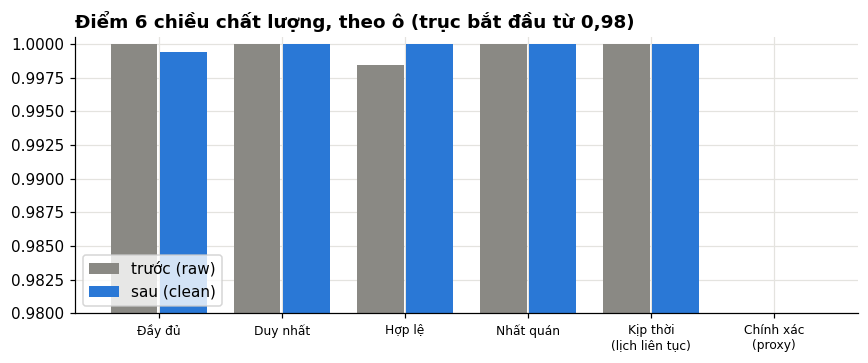

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(dims))
ax.bar(x - 0.2, [B[d]["theo ô"] for d in dims], width=0.38, color=GRAY, label="trước (raw)")
ax.bar(x + 0.2, [A[d]["theo ô"] for d in dims], width=0.38, color=BLUE, label="sau (clean)")
ax.set_ylim(0.98, 1.0005); ax.set_xticks(x, [d.replace(" (", "\n(") for d in dims], fontsize=8); ax.legend(loc="lower left")
ax.set_title("Điểm 6 chiều chất lượng, theo ô (trục bắt đầu từ 0,98)")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig_dq02_truoc_sau.png")); plt.show()

### Giám sát theo thời gian

Cùng các thước đo, tính riêng cho từng tuần của dữ liệu gốc, để xem chất lượng có thay đổi theo thời gian hay không.

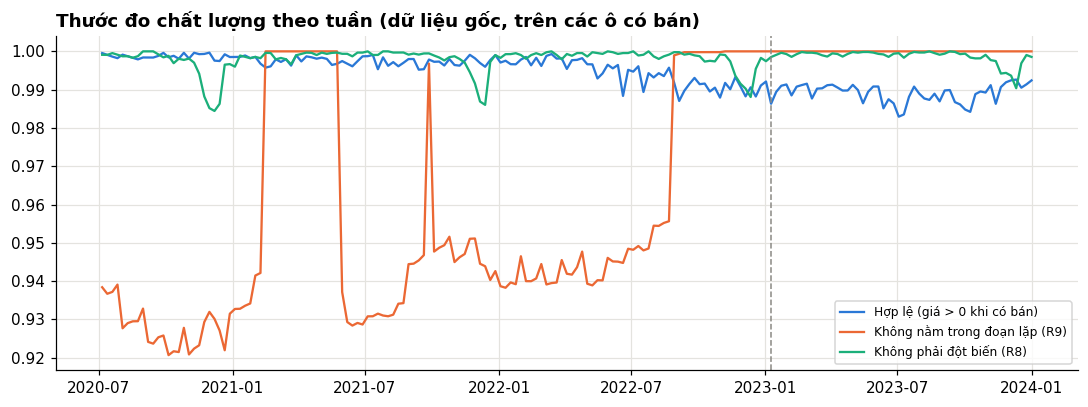

,hop_le_gia,nhat_quan,chinh_xac_proxy,khong_lap_R9,khong_dot_bien_R8
min,0.982943,1.000000,0.913389,0.920672,0.984434
mean,0.994258,1.000000,0.965242,0.967456,0.998126
max,0.999663,1.000000,0.999675,1.000000,1.000000


In [14]:
n_sale_w = sale.sum(axis=0)
mon = pd.DataFrame({"week": weeks,
                    "hop_le_gia": 1 - (sale & (Pv <= 0)).sum(axis=0) / n_sale_w,
                    "nhat_quan": 1 - ((~sale & ~p_empty) | (sale & p_empty)).sum(axis=0) / n_series,
                    "chinh_xac_proxy": 1 - proxy_err.sum(axis=0) / n_sale_w,
                    "khong_lap_R9": 1 - in_run.sum(axis=0) / n_sale_w,
                    "khong_dot_bien_R8": 1 - spike.sum(axis=0) / n_sale_w,
                    "so_chuoi_co_ban": n_sale_w})
mon.to_csv(os.path.join(OUT, "dq_weekly_monitor.csv"), index=False)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(mon["week"], mon["hop_le_gia"], color=BLUE, label="Hợp lệ (giá > 0 khi có bán)")
ax.plot(mon["week"], mon["khong_lap_R9"], color=ORANGE, label="Không nằm trong đoạn lặp (R9)")
ax.plot(mon["week"], mon["khong_dot_bien_R8"], color=AQUA, label="Không phải đột biến (R8)")
ax.axvline(weeks[n_train], color=GRAY, ls="--", lw=1); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Thước đo chất lượng theo tuần (dữ liệu gốc, trên các ô có bán)")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig_dq03_giam_sat_theo_tuan.png")); plt.show()
mon.describe().loc[["min", "mean", "max"], ["hop_le_gia", "nhat_quan", "chinh_xac_proxy", "khong_lap_R9", "khong_dot_bien_R8"]]

## 7. Kiểm tra rò rỉ: cờ "giá thiếu" có đoán được doanh số không

Huấn luyện hồi quy logistic dự đoán `sales > 0` chỉ từ một biến: ô giá có trống hay không. Điểm rò rỉ `s_leak = 1 − AUC`. AUC gần 1 nghĩa là biến này là lối tắt gần như hoàn hảo tới biến mục tiêu.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
def leak(indicator, target, name, n=400000):
    idx = rng.choice(indicator.size, min(n, indicator.size), replace=False)
    X, y = indicator.ravel()[idx].astype(float).reshape(-1, 1), target.ravel()[idx].astype(int)
    half = len(idx) // 2
    m = LogisticRegression().fit(X[:half], y[:half])
    auc = roc_auc_score(y[half:], m.predict_proba(X[half:])[:, 1])
    return {"biến dự đoán": name, "AUC": auc, "s_leak = 1 − AUC": 1 - auc, "hệ số": float(m.coef_[0, 0]), "số ô kiểm tra": len(idx) - half}
act = present.ravel()
leak_rows = [
    leak(p_empty, sale, "raw: ô giá trống (mọi ô Phase 0+1)"),
    leak(np.isnan(cPraw)[present], csale[present], "clean: price_raw trống (từ tuần bán đầu)"),
    leak(np.isnan(cP)[present], csale[present], "clean: price (đã điền) trống"),
]
leak_df = pd.DataFrame(leak_rows)
leak_df.to_csv(os.path.join(OUT, "dq_leakage.csv"), index=False)
leak_df

,biến dự đoán,AUC,s_leak = 1 − AUC,hệ số,số ô kiểm tra
0,raw: ô giá trống (mọi ô Phase 0+1),1.000000,0.000000,-16,200000
1,clean: price_raw trống (từ tuần bán đầu),1.000000,0.000000,-16,200000
2,clean: price (đã điền) trống,0.500346,0.499654,-0.268809,200000


## 8. Tóm tắt

In [16]:
r = {x["quy tắc"][:3].strip(): x for x in rules}
n_all_zero_price = int((zero_price_sale.sum(axis=1) == sale.sum(axis=1))[sale.any(axis=1)].sum())
fmt = lambda v: f"{int(v):,}".replace(",", ".")
box = f"""
**Ô Chất lượng**

- **Dòng trùng:** 0 dòng trùng hoàn toàn và 0 khóa trùng trong cả 5 file gốc; 0 cặp (chuỗi, tuần) trùng trong bảng dài.
- **Ô trống:** file Sales không có ô trống. File Price trống {miss.loc[1, '% trống']:.2f}% (Phase 0) và {miss.loc[3, '% trống']:.2f}% (Phase 1), và **toàn bộ** là ô "không áp dụng": giá trống khi và chỉ khi tuần đó không bán ({fmt(struct.loc[0, 'số ô'])} ô). Không có ô nào có bán mà thiếu giá, và không có ô nào không bán mà có giá.
- **Giá trị giả dạng thiếu:** không có chuỗi ký tự kiểu 'nan', 'unknown', '-' và không có giá trị âm. Có {fmt(zero_price_sale.sum())} ô giá bằng 0 ở tuần có bán ({r['R3']['%']:.2f}% số ô có bán), thuộc {fmt(zero_price_sale.any(axis=1).sum())} chuỗi; {n_all_zero_price} chuỗi có giá bằng 0 ở mọi tuần có bán nên không tính được doanh thu.
- **Mâu thuẫn:** các quy tắc miền giá trị và liên trường đều không có vi phạm, trừ giá bằng 0 nêu trên. Ba proxy về độ chính xác có vi phạm: giá nhảy hơn 10 lần giữa hai tuần liền nhau ({fmt(r['R7']['vi phạm'])} cặp, {r['R7']['%']:.3f}%), cùng sản phẩm cùng tuần mà giá chênh hơn 10 lần giữa các chuỗi ({fmt(r['R6']['vi phạm'])} cặp, {r['R6']['%']:.2f}%), đột biến hơn 20 lần trung vị ({fmt(r['R8']['vi phạm'])} ô, {r['R8']['%']:.2f}%).
- **Giá trị lặp:** {fmt(r['R9']['vi phạm'])} ô có bán ({r['R9']['%']:.2f}%) nằm trong đoạn lặp lại y hệt từ 13 tuần liên tiếp, thuộc {fmt(in_run.any(axis=1).sum())} chuỗi. Đây là dấu hiệu giá trị được điền chứ không phải doanh số ghi nhận hàng tuần.
- **Sáu chiều (theo ô, trước → sau):** Đầy đủ {B['Đầy đủ']['theo ô']:.4f} → {A['Đầy đủ']['theo ô']:.4f}; Duy nhất {B['Duy nhất']['theo ô']:.4f} → {A['Duy nhất']['theo ô']:.4f}; Hợp lệ {B['Hợp lệ']['theo ô']:.4f} → {A['Hợp lệ']['theo ô']:.4f}; Nhất quán {B['Nhất quán']['theo ô']:.4f} → {A['Nhất quán']['theo ô']:.4f}; Chính xác (proxy) {acc_b['theo ô']:.4f}, không đổi.
- **Rò rỉ:** cờ "giá trống" dự đoán `sales > 0` với AUC = {leak_rows[0]['AUC']:.4f} trên dữ liệu gốc (s_leak = {leak_rows[0]['s_leak = 1 − AUC']:.4f}). Không được dùng cờ này hay `price_raw` làm đặc trưng.

**Ô Thời gian**

- **Khoảng dữ liệu:** {weeks[0].date()} đến {weeks[-1].date()} ({n_weeks} tuần có số lượng và giá), cộng Phase 2 từ {w2[0].date()} đến {w2[-1].date()} ({len(w2)} tuần, chỉ có số lượng).
- **Lịch:** mọi cột tuần là thứ Hai, cách nhau đúng 7 ngày, không thiếu tuần nào; ba phase nối liền nhau, không chồng và không hở.
- **Số tuần theo năm (Phase 0+1):** {', '.join(f'{y}: {int(v)}' for y, v in per_year['số tuần (Phase 0+1)'].items())}.
- **Chia tập:** huấn luyện {n_train} tuần (đến {weeks[n_train - 1].date()}), kiểm tra {TEST_WEEKS} tuần (từ {weeks[n_train].date()}). Trong tập kiểm tra có {TEST_WEEKS // H} mốc dự báo 13 tuần không chồng nhau, hoặc {TEST_WEEKS - H + 1} mốc nếu trượt từng tuần.
- **Cắt trái:** {fmt((first_idx == 0).sum())} chuỗi đã bán ngay tuần đầu của dữ liệu nên ngày ra mắt thật không biết. {fmt((first_idx >= n_train).sum())} chuỗi có lần bán đầu tiên nằm trong tập kiểm tra.
- **Kịp thời:** dữ liệu kết thúc {w2[-1].date()}, cách hôm nay ({today.date()}) {age_weeks} tuần. Dùng cho nghiên cứu và so sánh phương pháp thì không ảnh hưởng; không dùng được để dự báo vận hành hiện tại.
- **Đơn vị giá:** không rõ loại tiền. Giá trung vị của chuỗi là {np.nanmedian(med_series):.1f}; 1% đến 99% số ô nằm trong khoảng {q[1]:.2f} đến {q[5]:,.0f}.
"""
with open(os.path.join(OUT, "dq_summary.md"), "w", encoding="utf-8") as f:
    f.write(box)
display(Markdown(box))


**Ô Chất lượng**

- **Dòng trùng:** 0 dòng trùng hoàn toàn và 0 khóa trùng trong cả 5 file gốc; 0 cặp (chuỗi, tuần) trùng trong bảng dài.
- **Ô trống:** file Sales không có ô trống. File Price trống 71.76% (Phase 0) và 56.24% (Phase 1), và **toàn bộ** là ô "không áp dụng": giá trống khi và chỉ khi tuần đó không bán (1.946.496 ô). Không có ô nào có bán mà thiếu giá, và không có ô nào không bán mà có giá.
- **Giá trị giả dạng thiếu:** không có chuỗi ký tự kiểu 'nan', 'unknown', '-' và không có giá trị âm. Có 5.605 ô giá bằng 0 ở tuần có bán (0.69% số ô có bán), thuộc 1.657 chuỗi; 64 chuỗi có giá bằng 0 ở mọi tuần có bán nên không tính được doanh thu.
- **Mâu thuẫn:** các quy tắc miền giá trị và liên trường đều không có vi phạm, trừ giá bằng 0 nêu trên. Ba proxy về độ chính xác có vi phạm: giá nhảy hơn 10 lần giữa hai tuần liền nhau (354 cặp, 0.053%), cùng sản phẩm cùng tuần mà giá chênh hơn 10 lần giữa các chuỗi (3.357 cặp, 3.08%), đột biến hơn 20 lần trung vị (1.495 ô, 0.18%).
- **Giá trị lặp:** 20.557 ô có bán (2.54%) nằm trong đoạn lặp lại y hệt từ 13 tuần liên tiếp, thuộc 374 chuỗi. Đây là dấu hiệu giá trị được điền chứ không phải doanh số ghi nhận hàng tuần.
- **Sáu chiều (theo ô, trước → sau):** Đầy đủ 1.0000 → 0.9994; Duy nhất 1.0000 → 1.0000; Hợp lệ 0.9984 → 1.0000; Nhất quán 1.0000 → 1.0000; Chính xác (proxy) 0.9723, không đổi.
- **Rò rỉ:** cờ "giá trống" dự đoán `sales > 0` với AUC = 1.0000 trên dữ liệu gốc (s_leak = 0.0000). Không được dùng cờ này hay `price_raw` làm đặc trưng.

**Ô Thời gian**

- **Khoảng dữ liệu:** 2020-07-06 đến 2024-01-01 (183 tuần có số lượng và giá), cộng Phase 2 từ 2024-01-08 đến 2024-04-01 (13 tuần, chỉ có số lượng).
- **Lịch:** mọi cột tuần là thứ Hai, cách nhau đúng 7 ngày, không thiếu tuần nào; ba phase nối liền nhau, không chồng và không hở.
- **Số tuần theo năm (Phase 0+1):** 2020: 26, 2021: 52, 2022: 52, 2023: 52, 2024: 1.
- **Chia tập:** huấn luyện 131 tuần (đến 2023-01-02), kiểm tra 52 tuần (từ 2023-01-09). Trong tập kiểm tra có 4 mốc dự báo 13 tuần không chồng nhau, hoặc 40 mốc nếu trượt từng tuần.
- **Cắt trái:** 2.224 chuỗi đã bán ngay tuần đầu của dữ liệu nên ngày ra mắt thật không biết. 3.727 chuỗi có lần bán đầu tiên nằm trong tập kiểm tra.
- **Kịp thời:** dữ liệu kết thúc 2024-04-01, cách hôm nay (2026-10-13) 132 tuần. Dùng cho nghiên cứu và so sánh phương pháp thì không ảnh hưởng; không dùng được để dự báo vận hành hiện tại.
- **Đơn vị giá:** không rõ loại tiền. Giá trung vị của chuỗi là 30.0; 1% đến 99% số ô nằm trong khoảng 2.16 đến 1,349.


## 9. Kiểm tra bổ sung: cách ghi số lượng của nhà bán hàng 0

Quy tắc R9 cho thấy các đoạn lặp tập trung ở nhà bán hàng 0. Ô dưới đây đo tỷ lệ ô có bán mà số lượng là bội số của 7, theo quý, cho nhà bán hàng 0 và cho các nhà bán hàng còn lại.

In [17]:
client_arr = S.index.get_level_values("Client").to_numpy()
c0 = client_arr == 0
quarter = weeks.to_period("Q")
def mult7(mask_rows, cols):
    x = Sv[mask_rows][:, cols]; x = x[x > 0]
    return (x % 7 == 0).mean() if len(x) else np.nan
m7 = pd.DataFrame({"nhà bán hàng 0": [mult7(c0, quarter == q_) for q_ in quarter.unique()],
                   "nhà bán hàng khác": [mult7(~c0, quarter == q_) for q_ in quarter.unique()]}, index=quarter.unique().astype(str))
m7.index.name = "quý"
m7.to_csv(os.path.join(OUT, "dq_client0_multiples_of_7.csv"))
rev_cell = np.where(Pv > 0, Sv * Pv, 0.0)
c0_train = rev_cell[c0, :n_train].sum() / rev_cell[:, :n_train].sum()
c0_test = rev_cell[c0, n_train:].sum() / rev_cell[:, n_train:].sum()
c0_m7_train, c0_m7_test = mult7(c0, np.arange(n_weeks) < n_train), mult7(c0, np.arange(n_weeks) >= n_train)
print(f"Nhà bán hàng 0: {c0.sum()} chuỗi ({c0.mean():.1%} số chuỗi), {c0_train:.1%} doanh thu huấn luyện, {c0_test:.1%} doanh thu kiểm tra.")
print(f"Tỷ lệ bội số của 7 ở nhà bán hàng 0: {c0_m7_train:.1%} (huấn luyện) so với {c0_m7_test:.1%} (kiểm tra).")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
m7.T

Nhà bán hàng 0: 930 chuỗi (6.2% số chuỗi), 32.0% doanh thu huấn luyện, 21.3% doanh thu kiểm tra.
Tỷ lệ bội số của 7 ở nhà bán hàng 0: 75.2% (huấn luyện) so với 9.9% (kiểm tra).


quý,2020Q3,2020Q4,2021Q1,2021Q2,2021Q3,2021Q4,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1
nhà bán hàng 0,0.873,0.880,0.896,0.578,0.858,0.918,0.884,0.886,0.669,0.104,0.101,0.099,0.095,0.102,0.090
nhà bán hàng khác,0.084,0.084,0.081,0.080,0.081,0.085,0.083,0.083,0.084,0.086,0.086,0.084,0.081,0.084,0.086


Trước khoảng tháng 9/2022, gần 9 trong 10 ô có bán của nhà bán hàng 0 là bội số của 7; từ quý 4/2022 tỷ lệ này về ngang các nhà bán hàng khác. Có hai cách hiểu: (a) đây là nhà bán hàng lớn, bán rất đều; (b) trong giai đoạn đầu, số liệu tuần của nhà bán hàng này được suy ra từ một con số thô hơn rồi chia đều. Số liệu nghiêng về (b) vì sự thay đổi xảy ra đồng loạt ở mọi chuỗi vào cùng thời điểm, nhưng tài liệu của bộ dữ liệu không xác nhận. Toàn bộ giai đoạn kiểm tra nằm sau thời điểm thay đổi.

## 10. Kết luận: bộ dữ liệu có phù hợp với bài toán không

In [18]:
verdict = f"""
**Đề tài:** Dự báo doanh thu 13 tuần tới theo nhóm kiểu nhu cầu cho sản phẩm của nhà bán hàng trực tuyến (dữ liệu VN1)

**Bài toán:** Với mỗi chuỗi nhà bán hàng × kho × sản phẩm, dùng lịch sử bán hàng theo tuần đến thời điểm dự báo để dự báo doanh thu của từng tuần trong 13 tuần kế tiếp; chuỗi được chia nhóm theo kiểu nhu cầu và mỗi nhóm dùng phương pháp phù hợp; đánh giá bằng điểm VN1 (MAE% + |Bias%|) trên bốn kỳ 13 tuần của 52 tuần cuối. Huấn luyện {n_train} tuần, kiểm tra {TEST_WEEKS} tuần.

**Kết luận: VN1 là bộ dữ liệu tốt và phù hợp với bài toán này, với điều kiện ghi rõ bốn giới hạn bên dưới.**

| Yêu cầu của bài toán | Dữ liệu đáp ứng thế nào | Đánh giá |
|---|---|---|
| Chuỗi thời gian tuần liên tục, không hở | {len(full_cal)} tuần liên tục, mọi cột là thứ Hai, không thiếu tuần nào | Đạt |
| Mỗi chuỗi được định danh duy nhất | 0 khóa trùng trong 5 file; {fmt(n_series)} chuỗi có mặt ở cả 5 file | Đạt |
| Giá trị hợp lệ | Không có số âm, không có số lượng lẻ; {r['R3']['%']:.2f}% ô có bán có giá bằng 0, đã xử lý | Đạt |
| Tính được doanh thu | Có giá ở mọi tuần có bán; {n_all_zero_price} chuỗi không có giá hợp lệ phải loại khỏi phần doanh thu | Đạt, có ngoại lệ nhỏ |
| Đủ dài để chia tập và trượt mốc | {n_weeks} tuần; {TEST_WEEKS // H} mốc 13 tuần không chồng nhau, hoặc {TEST_WEEKS - H + 1} mốc trượt | Đạt |
| Đủ đa dạng để phân nhóm kiểu nhu cầu | Có đủ cả bốn nhóm Syntetos-Boylan với số lượng lớn | Đạt |
| Không rò rỉ từ đặc trưng sang mục tiêu | Giá gốc rò rỉ hoàn toàn (AUC = {leak_rows[0]['AUC']:.2f}); cột giá đã điền thì không (AUC = {leak_rows[2]['AUC']:.2f}) | Đạt sau làm sạch |
| Độ chính xác so với thực tế | Không có nguồn tham chiếu; proxy = {acc_b['theo ô']:.4f} | Không kiểm chứng được |
| Học được mùa vụ ở từng chuỗi | Huấn luyện chỉ chứa ba mùa cuối năm, nhiều chuỗi ra mắt muộn | Hạn chế |

**Bốn giới hạn cần ghi trong báo cáo**

1. **Dự báo doanh số đã ghi nhận, không phải nhu cầu.** Không có dữ liệu tồn kho nên tuần bằng 0 có thể là hết hàng hoặc không ai mua.
2. **Chiều Chính xác chỉ đo bằng proxy.** "Chất lượng tốt" ở đây nghĩa là nhất quán nội tại, chưa được đối chiếu với nguồn bên ngoài.
3. **Nhà bán hàng 0** ({c0.sum()} chuỗi, {c0_train:.0%} doanh thu huấn luyện, {c0_test:.0%} doanh thu kiểm tra) có số lượng là bội số của 7 ở {c0_m7_train:.0%} số ô có bán trong giai đoạn huấn luyện, so với {c0_m7_test:.0%} trong giai đoạn kiểm tra. Nên báo cáo sai số dự báo tách riêng nhà bán hàng này.
4. **Chuỗi mới và chuỗi ngắn.** {fmt((first_idx >= n_train).sum())} chuỗi có lần bán đầu tiên nằm trong giai đoạn kiểm tra, nên phải đánh giá bằng mốc trượt và có phương án riêng cho chuỗi thiếu lịch sử.

Không giới hạn nào trong bốn điều trên làm bài toán không thực hiện được; chúng quyết định cách đánh giá và cách diễn giải kết quả.
"""
with open(os.path.join(OUT, "dq_conclusion.md"), "w", encoding="utf-8") as f:
    f.write(verdict)
display(Markdown(verdict))


**Đề tài:** Dự báo doanh thu 13 tuần tới theo nhóm kiểu nhu cầu cho sản phẩm của nhà bán hàng trực tuyến (dữ liệu VN1)

**Bài toán:** Với mỗi chuỗi nhà bán hàng × kho × sản phẩm, dùng lịch sử bán hàng theo tuần đến thời điểm dự báo để dự báo doanh thu của từng tuần trong 13 tuần kế tiếp; chuỗi được chia nhóm theo kiểu nhu cầu và mỗi nhóm dùng phương pháp phù hợp; đánh giá bằng điểm VN1 (MAE% + |Bias%|) trên bốn kỳ 13 tuần của 52 tuần cuối. Huấn luyện 131 tuần, kiểm tra 52 tuần.

**Kết luận: VN1 là bộ dữ liệu tốt và phù hợp với bài toán này, với điều kiện ghi rõ bốn giới hạn bên dưới.**

| Yêu cầu của bài toán | Dữ liệu đáp ứng thế nào | Đánh giá |
|---|---|---|
| Chuỗi thời gian tuần liên tục, không hở | 196 tuần liên tục, mọi cột là thứ Hai, không thiếu tuần nào | Đạt |
| Mỗi chuỗi được định danh duy nhất | 0 khóa trùng trong 5 file; 15.053 chuỗi có mặt ở cả 5 file | Đạt |
| Giá trị hợp lệ | Không có số âm, không có số lượng lẻ; 0.69% ô có bán có giá bằng 0, đã xử lý | Đạt |
| Tính được doanh thu | Có giá ở mọi tuần có bán; 64 chuỗi không có giá hợp lệ phải loại khỏi phần doanh thu | Đạt, có ngoại lệ nhỏ |
| Đủ dài để chia tập và trượt mốc | 183 tuần; 4 mốc 13 tuần không chồng nhau, hoặc 40 mốc trượt | Đạt |
| Đủ đa dạng để phân nhóm kiểu nhu cầu | Có đủ cả bốn nhóm Syntetos-Boylan với số lượng lớn | Đạt |
| Không rò rỉ từ đặc trưng sang mục tiêu | Giá gốc rò rỉ hoàn toàn (AUC = 1.00); cột giá đã điền thì không (AUC = 0.50) | Đạt sau làm sạch |
| Độ chính xác so với thực tế | Không có nguồn tham chiếu; proxy = 0.9723 | Không kiểm chứng được |
| Học được mùa vụ ở từng chuỗi | Huấn luyện chỉ chứa ba mùa cuối năm, nhiều chuỗi ra mắt muộn | Hạn chế |

**Bốn giới hạn cần ghi trong báo cáo**

1. **Dự báo doanh số đã ghi nhận, không phải nhu cầu.** Không có dữ liệu tồn kho nên tuần bằng 0 có thể là hết hàng hoặc không ai mua.
2. **Chiều Chính xác chỉ đo bằng proxy.** "Chất lượng tốt" ở đây nghĩa là nhất quán nội tại, chưa được đối chiếu với nguồn bên ngoài.
3. **Nhà bán hàng 0** (930 chuỗi, 32% doanh thu huấn luyện, 21% doanh thu kiểm tra) có số lượng là bội số của 7 ở 75% số ô có bán trong giai đoạn huấn luyện, so với 10% trong giai đoạn kiểm tra. Nên báo cáo sai số dự báo tách riêng nhà bán hàng này.
4. **Chuỗi mới và chuỗi ngắn.** 3.727 chuỗi có lần bán đầu tiên nằm trong giai đoạn kiểm tra, nên phải đánh giá bằng mốc trượt và có phương án riêng cho chuỗi thiếu lịch sử.

Không giới hạn nào trong bốn điều trên làm bài toán không thực hiện được; chúng quyết định cách đánh giá và cách diễn giải kết quả.
